In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/data/Ames_Housing_Sales.csv")
data.head()

,1stFlrSF,2ndFlrSF,3SsnPorch,Alley,BedroomAbvGr,BldgType,BsmtCond,BsmtExposure,BsmtFinSF1,BsmtFinSF2,...,ScreenPorch,Street,TotRmsAbvGrd,TotalBsmtSF,Utilities,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold,SalePrice
0,856.0,854.0,0.0,NaN,3,1Fam,TA,No,706.0,0.0,...,0.0,Pave,8,856.0,AllPub,0.0,2003,2003,2008,208500.0
1,1262.0,0.0,0.0,NaN,3,1Fam,TA,Gd,978.0,0.0,...,0.0,Pave,6,1262.0,AllPub,298.0,1976,1976,2007,181500.0
2,920.0,866.0,0.0,NaN,3,1Fam,TA,Mn,486.0,0.0,...,0.0,Pave,6,920.0,AllPub,0.0,2001,2002,2008,223500.0
3,961.0,756.0,0.0,NaN,3,1Fam,Gd,No,216.0,0.0,...,0.0,Pave,7,756.0,AllPub,0.0,1915,1970,2006,140000.0
4,1145.0,1053.0,0.0,NaN,4,1Fam,TA,Av,655.0,0.0,...,0.0,Pave,9,1145.0,AllPub,192.0,2000,2000,2008,250000.0


In [3]:
data_ohc = data.copy()
categorical_cols = data_ohc.select_dtypes(include=['object']).columns

le = LabelEncoder()
ohc = OneHotEncoder()

for col in categorical_cols:
    dat = le.fit_transform(data_ohc[col]).astype(int)
    data_ohc = data_ohc.drop(col, axis=1) 
    
    new_dat = ohc.fit_transform(dat.reshape(-1,1))
    n_cols = new_dat.shape[1]
    col_names = ['_'.join([col, str(x)]) for x in range(n_cols)]
    
    new_df = pd.DataFrame(new_dat.toarray(), index=data_ohc.index, columns=col_names)
    data_ohc = pd.concat([data_ohc, new_df], axis=1)

C:\Users\ACER\AppData\Local\Temp\ipykernel_19976\1342476288.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = data_ohc.select_dtypes(include=['object']).columns


In [4]:
y_col = 'SalePrice'
feature_cols = [x for x in data_ohc.columns if x != y_col]
X_train, X_test, y_train, y_test = train_test_split(data_ohc[feature_cols], data_ohc[y_col], test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Mean Squared Error (Test): 13191793683.687414


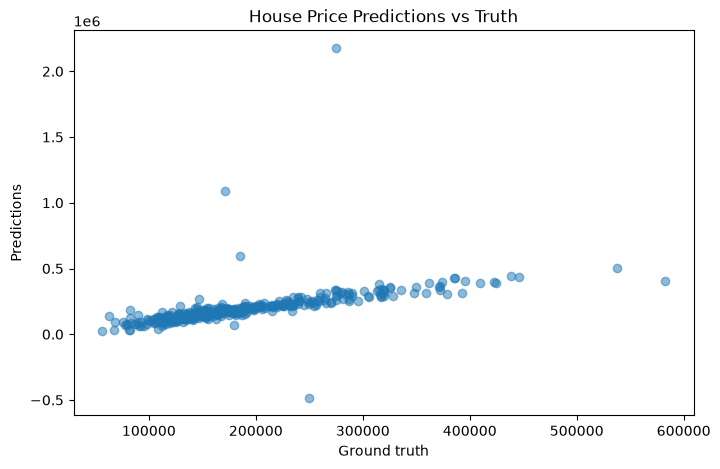

In [5]:
LR = LinearRegression()
LR.fit(X_train_scaled, y_train)

y_test_pred = LR.predict(X_test_scaled)
print("Mean Squared Error (Test):", mean_squared_error(y_test, y_test_pred))

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_test_pred, alpha=.5)
plt.xlabel('Ground truth')
plt.ylabel('Predictions')
plt.title('House Price Predictions vs Truth')
plt.show()